# Урок 9. Разбор двух больших задач

Здесь решения **только двух основных практических работ** из `machine_learning_basics.ipynb`: прогноз топлива и подлинность артефакта. Десять маленьких упражнений из архива не разбираются.

Цель — пройти путь, который нужен на реальном соревновании: понять таблицу, убрать признаки из будущего, отделить валидацию, подготовить числа и категории, сравнить несколько простых вариантов, обучить итоговую модель и сохранить ответ. Код намеренно прямой. Графики используются только для проверки данных и ошибок.

Запускайте ячейки сверху вниз из папки урока 9. Нужны `numpy`, `pandas`, `scikit-learn`, `matplotlib`.

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score,
                             f1_score, log_loss, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

## Общая схема честной проверки

В обоих заданиях у нас есть `train.csv` с ответами и `test.csv` без ответов. Для оценки качества сначала делим **train** на две части: одну для обучения, вторую для валидации. Всё, что надо *изучить из данных* — медианы, средние, стандартные отклонения, список one-hot колонок — считаем только на обучающей части. Валидационная часть и официальный test получают уже готовые преобразования. После выбора параметров обучаем на **всём train** и готовим файл для test. Его настоящее качество посчитать нельзя: в test нет правильного ответа.

Если случайно подмешать в признаки колонку, появляющуюся после полёта или после лабораторной экспертизы, получится утечка. Модель может показывать прекрасный результат на локальной проверке, но не сможет работать в нужный момент. Смысл колонки важнее её корреляции с ответом.

**Почему так строго?** Если заполнить пропуски или стандартизировать столбцы по всей таблице до разделения, в обучении появится информация о валидации. Она небольшая, но оценка уже не будет полностью честной. Сначала разделение, затем `fit` преобразований на обучающей части, затем их применение к остальным строкам.

### Как читать метрики

| Метрика | Что означает | Хорошее направление |
|---|---|---|
| MAE | Средний размер ошибки без учёта знака; в задаче 1 — литры | Меньше |
| MSE | Средний квадрат ошибки; крупные промахи влияют сильнее | Меньше |
| R² | Насколько модель лучше прогноза одним средним числом; может быть отрицательным | Ближе к 1 |
| Accuracy | Доля всех верных решений | Больше, но при редком классе бывает обманчива |
| Precision | Какая доля названных подлинниками действительно подлинна | Больше |
| Recall | Какую долю настоящих подлинников нашли | Больше |
| F1 | Одно число, учитывающее precision и recall | Больше |
| Log loss | Насколько хороши вероятности; уверенная ошибка дорого обходится | Меньше |

Оценивать эти числа нужно **на валидации**, а не на тех строках, по которым модель училась.

## Простая функция подготовки таблиц для линейных моделей

Используем один и тот же порядок для обеих задач:

1. Числовые пропуски заполняем **медианами обучающей части**.
2. Пропуски категорий заменяем строкой `unknown`.
3. Категории превращаем в нули и единицы через `get_dummies`.
4. Таблицу валидации/test выравниваем по столбцам обучения. Если там появилась новая категория, её столбец не добавляется модели: для этой категории все известные индикаторы равны нулю.
5. Масштабируем **только исходные числовые столбцы** через `StandardScaler`, обученный на train. Это важно для штрафа за веса в Ridge и LogisticRegression.

Функция обучает статистики на `fit_table`, преобразует две таблицы и возвращает их. Для финального test вызовем её ещё раз на **полном train**, что разрешено: перед финальным обучением мы уже выбрали параметры.

In [72]:
def prepare_tables(fit_table, other_table):
    fit_table = fit_table.copy()
    other_table = other_table.copy()

    number_columns = fit_table.select_dtypes(include='number').columns.tolist()
    category_columns = [column for column in fit_table.columns if column not in number_columns]

    medians = fit_table[number_columns].median()
    fit_table[number_columns] = fit_table[number_columns].fillna(medians)
    other_table[number_columns] = other_table[number_columns].fillna(medians)

    for column in category_columns:
        fit_table[column] = fit_table[column].astype('string').fillna('unknown')
        other_table[column] = other_table[column].astype('string').fillna('unknown')

    fit_table = pd.get_dummies(fit_table, columns=category_columns, dtype=int)
    other_table = pd.get_dummies(other_table, columns=category_columns, dtype=int)
    other_table = other_table.reindex(columns=fit_table.columns, fill_value=0)

    scaler = StandardScaler()
    fit_table[number_columns] = scaler.fit_transform(fit_table[number_columns])
    other_table[number_columns] = scaler.transform(other_table[number_columns])

    return fit_table, other_table

**Как пользоваться функцией:** `fit_table` — строки, на которых мы учимся; `other_table` — строки, для которых готовим признаки. Например, если новая погода встретилась только в валидации, модель не получит внезапно новый столбец: `reindex` оставит ровно те же колонки, что были при обучении. `StandardScaler` приводит числовые признаки к сопоставимому масштабу: вычитает среднее обучения и делит на его стандартное отклонение. Сама функция прогнозов не делает — после неё ещё нужны `model.fit` и `model.predict`.

# Задача 1. Сколько топлива потребуется рейсу на Марсе?

Цель — `fuel_used_liters`, числовой расход топлива. В файле test её нет. Итоговый файл должен содержать `flight_id` и наш прогноз. В условии предложены Ridge/Lasso; начнём с Ridge: один параметр `alpha` контролирует штраф за большие веса. В качестве основной метрики выберем **MAE** — средний размер ошибки в литрах. Дополнительно покажем MSE и $R^2$.

In [73]:
fuel_train = pd.read_csv('task1_train.csv')
fuel_test = pd.read_csv('task1_test.csv')
print(fuel_train.shape, fuel_test.shape)
fuel_train.head()

(1000, 21) (1000, 20)


,flight_id,mission_day,sector,reactor_model,weather_code,cargo_mass_kg,distance_km,distance_miles_redundant,dust_level,solar_index,...,radio_temperature_text,crew_experience_years,noise_sensor_1,noise_sensor_2,noise_sensor_3,noise_sensor_4,noise_sensor_5,after_flight_fuel_estimate,logbook_status_after_landing,fuel_used_liters
0,MARS-101-0000,390,Utopia,hybrid,clear,62.68,283.98,175.74,6.157,579.29,...,-33.9,2,1.823811,-0.014224,-0.463608,-1.971725,1.114077,442.88,high_consumption,442.95
1,MARS-101-0001,179,Elysium,hybrid,clear,207.16,207.88,127.79,0.780,511.22,...,-43.3,5,-0.237739,-0.278302,-2.341320,0.409127,-0.602052,348.93,normal_consumption,350.76
2,MARS-101-0002,680,Valles,ion,dust,45.12,207.94,129.95,6.466,305.44,...,-21.6,1,1.226652,-0.032990,1.907640,-2.003079,-0.050803,408.41,normal_consumption,405.60
3,MARS-101-0003,575,Valles,plasma,dust,103.47,237.81,148.06,8.031,508.64,...,-29.0,9,-2.104185,-0.923968,-0.431922,0.520262,1.547872,655.57,high_consumption,657.29
4,MARS-101-0004,279,Ares,ion,dust,129.05,174.22,108.23,4.166,412.16,...,-63.2,10,1.990896,0.817727,-0.775745,-0.044621,-0.525662,363.39,normal_consumption,370.01


In [74]:
print('Пропуски:')
print(fuel_train.isna().sum())

Пропуски:
flight_id                         0
mission_day                       0
sector                            0
reactor_model                    41
weather_code                      0
cargo_mass_kg                     0
distance_km                       0
distance_miles_redundant          0
dust_level                        0
solar_index                       0
temperature_c                   103
radio_temperature_text            0
crew_experience_years             0
noise_sensor_1                    0
noise_sensor_2                    0
noise_sensor_3                    0
noise_sensor_4                    0
noise_sensor_5                    0
after_flight_fuel_estimate        0
logbook_status_after_landing      0
fuel_used_liters                  0
dtype: int64


**Что видно:** в обоих файлах по 1000 рейсов. Ответ есть только в `train`. В нём 41 пропуск `reactor_model` и 103 пропуска `temperature_c`. Столбец `radio_temperature_text` пока текстовый, поэтому обычная модель не сможет сразу использовать его как число. Следующий шаг — посмотреть связи между разрешёнными признаками и расходом.

### Какие колонки опасны и что с ними сделать

- `after_flight_fuel_estimate` и `logbook_status_after_landing` появляются после посадки. Их надо удалить **и из train, и из test**.
- `flight_id` нужен для ответа, но не для обучения: это уникальный номер рейса, а не физическая характеристика.
- `distance_miles_redundant` повторяет `distance_km` в других единицах. Оставим один из них: модель не должна тратить веса на копии одного сигнала.
- `radio_temperature_text` содержит текстовые числа и `sensor_off`. Превратим в число; неудачные строки станут пропусками и позже будут заполнены медианой обучения.

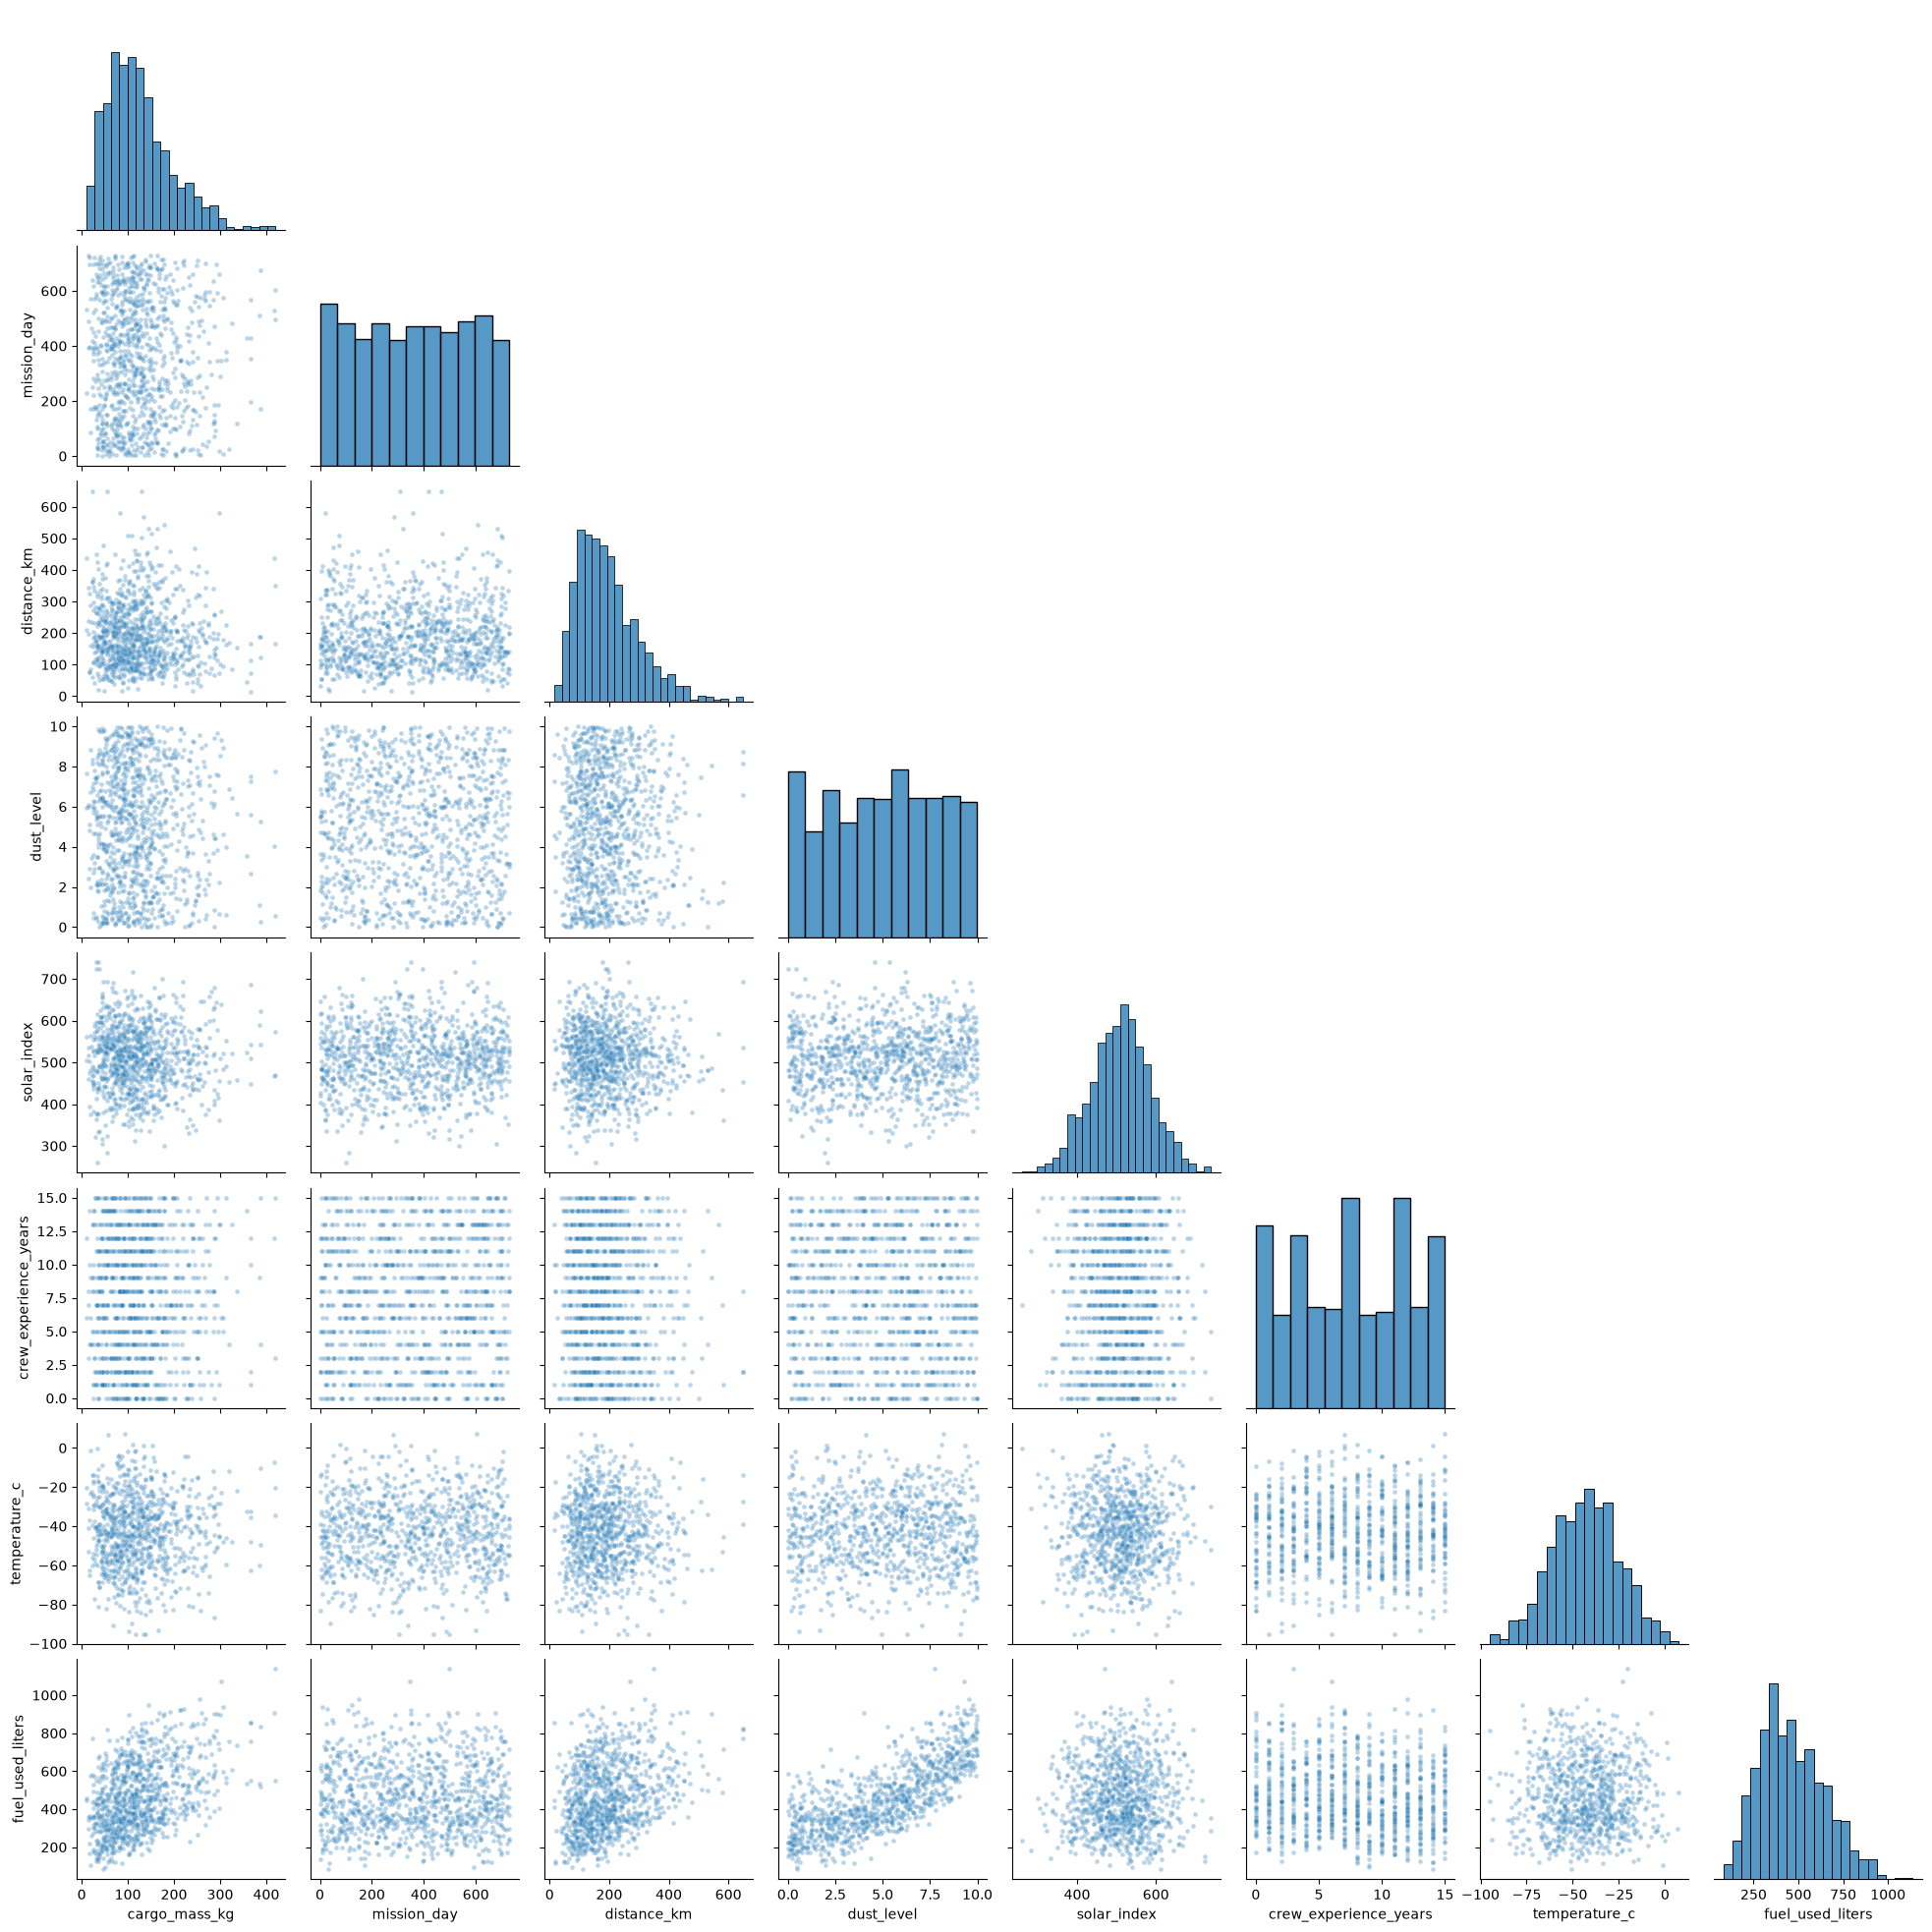

In [75]:
sns.pairplot(
    fuel_train[['cargo_mass_kg', 'mission_day',  'distance_km', 'dust_level', 'solar_index', 'crew_experience_years', 'temperature_c', 'fuel_used_liters']],
    corner=True, diag_kind='hist', plot_kws={'alpha': 0.3, 's': 12}
)

**Вывод по `pairplot`:** расход обычно растёт с уровнем пыли и массой груза; расстояние тоже связано с расходом. Облако точек для пыли не выглядит идеально прямым, поэтому позже проверим `dust_level ** 2`. Отдельные необычные точки пока оставляем: график сам по себе не доказывает ошибку измерения.

дополнительно взглянем есть ли какая то зависимость от значений noise_sensors

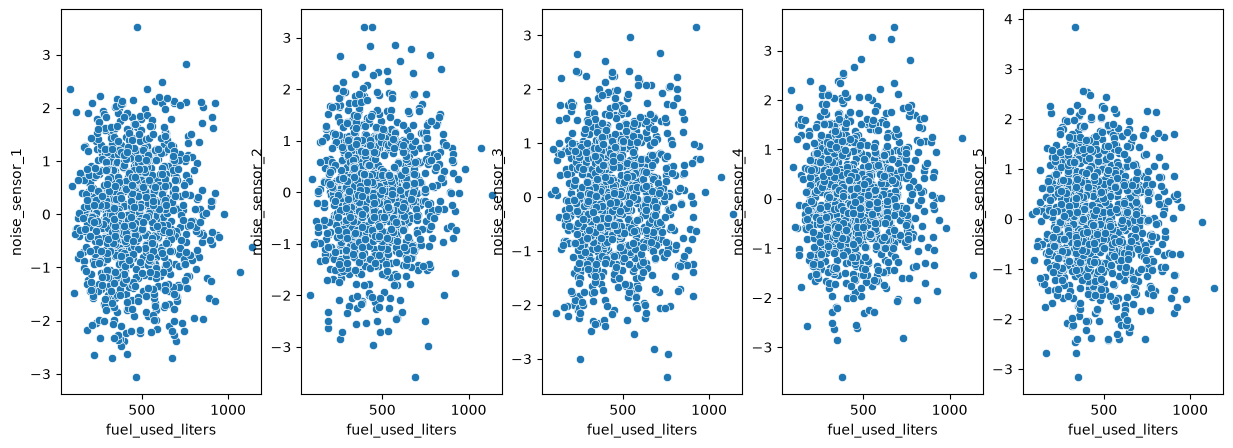

In [76]:
fig, axes = plt.subplots(1, 5, figsize=(15, 5))

for i in range(1, 6):
    sns.scatterplot(x=fuel_train['fuel_used_liters'], y=fuel_train[f'noise_sensor_{i}'], ax=axes[i-1])

plt.show()


видим что значения сенсоров не нужны

In [77]:
fuel_drop = ['flight_id', 'after_flight_fuel_estimate',
             'logbook_status_after_landing', 'distance_miles_redundant']

def fuel_features(table):
    features = table.drop(columns=fuel_drop).copy()
    features['radio_temperature_text'] = pd.to_numeric(
        features['radio_temperature_text'], errors='coerce'
    )
    return features

fuel_ids = fuel_test['flight_id'].copy()
X_fuel = fuel_features(fuel_train.drop(columns='fuel_used_liters'))
X_fuel_test = fuel_features(fuel_test)
y_fuel = fuel_train['fuel_used_liters'].copy()
print('sensor_off и другие нечитаемые значения:', X_fuel['radio_temperature_text'].isna().sum())
print('Новые категории погоды в test:', set(X_fuel_test['weather_code'].dropna()) - set(X_fuel['weather_code'].dropna()))

sensor_off и другие нечитаемые значения: 69
Новые категории погоды в test: {'solar_glare'}


**Что изменилось:** 69 строк `radio_temperature_text` стали пропусками после `to_numeric`: там были значения вроде `sensor_off`. В test есть новая погода `solar_glare`. Значит, пропуски надо заполнить по обучающей части, а one-hot столбцы test выровнять по train. Запрещённые колонки уже удалены до обучения.

### Валидация и простой ориентир

Разделим 1000 известных рейсов на обучение и валидацию 75/25. Для сравнения сначала будем предсказывать всем **средний расход обучающей части**. Если Ridge не превосходит такой ориентир, надо искать ошибку в данных или модели. Не берём среднее по всей таблице: это использовало бы ответы валидации.

In [78]:
Xf_train, Xf_valid, yf_train, yf_valid = train_test_split(
    X_fuel, y_fuel, test_size=0.25, random_state=RANDOM_STATE
)
mean_prediction = np.full(len(yf_valid), yf_train.mean())
print('MAE простого прогноза:', round(mean_absolute_error(yf_valid, mean_prediction), 2))
print('Разбивка:', Xf_train.shape, Xf_valid.shape)

MAE простого прогноза: 146.38
Разбивка: (750, 16) (250, 16)


**Ориентир:** постоянный прогноз ошибается в среднем на **146.38 л**. Хорошая модель должна заметно уменьшить MAE. 750 рейсов идут в обучение, 250 — в проверку; ответы этих 250 рейсов не использовались для заполнения пропусков или масштабирования.

### Проверим несколько простых вариантов

Сравним:

- `все`: исходные разрешённые признаки, в том числе шумовые датчики;
- `без шума`: удаляем пять явно шумовых столбцов;
- `пыль²`: к варианту без шума добавляем квадрат уровня пыли;
- `груз×пыль`: добавляем произведение массы груза и пыли.

Последние два признака — конкретные гипотезы о нелинейной связи, а не бесконечный перебор комбинаций. Для каждого варианта пробуем `alpha` из `[0.1, 1, 10, 100]`. **Меньше MAE на валидации — лучше.** Другие метрики посмотрим для выбранной модели. При переборе на одной валидации итоговая оценка может быть слегка оптимистична; для серьёзного соревнования лучше перекрёстная проверка.

In [79]:
noise_columns = [f'noise_sensor_{i}' for i in range(1, 6)]

def fuel_variant(table, variant):
    result = table.copy()
    if variant != 'все':
        result = result.drop(columns=noise_columns)
    if variant == 'пыль²':
        result['dust_squared'] = result['dust_level'] ** 2
    if variant == 'груз×пыль':
        result['cargo_dust'] = result['cargo_mass_kg'] * result['dust_level']
    return result

fuel_results = []
for variant in ['все', 'без шума', 'пыль²', 'груз×пыль']:
    candidate_train = fuel_variant(Xf_train, variant)
    candidate_valid = fuel_variant(Xf_valid, variant)
    ready_train, ready_valid = prepare_tables(candidate_train, candidate_valid)
    for alpha in [0.1, 1, 10, 100]:
        model = Ridge(alpha=alpha)
        model.fit(ready_train, yf_train)
        prediction = model.predict(ready_valid)
        fuel_results.append({'вариант': variant, 'alpha': alpha,
                             'MAE': mean_absolute_error(yf_valid, prediction),
                             'MSE': mean_squared_error(yf_valid, prediction),
                             'R²': r2_score(yf_valid, prediction)})

fuel_results = pd.DataFrame(fuel_results).sort_values('MAE')
fuel_results.round(3)

,вариант,alpha,MAE,MSE,R²
9,пыль²,1.0,25.569,1019.394,0.968
10,пыль²,10.0,25.585,1026.552,0.968
8,пыль²,0.1,25.598,1021.032,0.968
11,пыль²,100.0,30.462,1418.763,0.956
0,все,0.1,36.695,2034.200,0.937
1,все,1.0,36.697,2033.388,0.937
2,все,10.0,36.737,2032.334,0.937
5,без шума,1.0,37.121,2055.752,0.936
4,без шума,0.1,37.126,2056.468,0.936
6,без шума,10.0,37.142,2055.538,0.936


лучший здесь вариант — `пыль²`, `alpha=1`: MAE ≈ **25.57 л**, MSE ≈ **1019**, R² ≈ **0.968**. По сравнению с постоянным прогнозом средняя ошибка уменьшилась примерно в 5.7 раза. Квадрат пыли помог существенно; удаление шумовых датчиков *само по себе* на этой разбивке не улучшило MAE (`без шума` ≈ 37.12 л, `все` ≈ 36.70 л). Не надо заявлять, что любой шум обязательно вредит. Значения `alpha=0.1`, `1` и `10` для `пыль²` близки; выбираем минимальный MAE, не приписывая маленькой разнице большого смысла.

### Проверим выбранную модель

Берём вариант и `alpha` с минимальной **валидационной MAE** из таблицы. Для диагностики посмотрим ошибку на обучении и валидации: большой разрыв может намекать на переобучение. Остаток — это `настоящий расход − прогноз`. На графике остатков ищем систематический рисунок: если ошибки меняются с величиной прогноза, простой линейной модели может не хватать.

In [80]:
best_fuel = fuel_results.iloc[0]
best_variant = best_fuel['вариант']
best_alpha = best_fuel['alpha']
ready_fuel_train, ready_fuel_valid = prepare_tables(
    fuel_variant(Xf_train, best_variant), fuel_variant(Xf_valid, best_variant)
)
best_fuel_model = Ridge(alpha=best_alpha)
best_fuel_model.fit(ready_fuel_train, yf_train)
train_fuel_pred = best_fuel_model.predict(ready_fuel_train)
valid_fuel_pred = best_fuel_model.predict(ready_fuel_valid)
print('Выбрано:', best_variant, 'alpha =', best_alpha)
print('MAE train:', round(mean_absolute_error(yf_train, train_fuel_pred), 2))
print('MAE valid:', round(mean_absolute_error(yf_valid, valid_fuel_pred), 2))
print('MSE valid:', round(mean_squared_error(yf_valid, valid_fuel_pred), 2))
print('R² valid:', round(r2_score(yf_valid, valid_fuel_pred), 3))

Выбрано: пыль² alpha = 1.0
MAE train: 23.4
MAE valid: 25.57
MSE valid: 1019.39
R² valid: 0.968


**Проверка переобучения:** MAE на обучении ≈ **23.4 л**, на валидации ≈ **25.6 л**. Разрыв небольшой по сравнению с ошибкой постоянного прогноза; явного сильного переобучения здесь не видно.

### Обучение на всех известных рейсах и файл ответа

Теперь параметры выбраны. Снова готовим таблицы, но статистики берём уже из **полного train**, затем обучаем Ridge и предсказываем официальный test. Это нормально: теперь все 1000 ответов train можно использовать для финального обучения. `test` остаётся без ответов.

In [81]:
full_fuel, final_fuel = prepare_tables(
    fuel_variant(X_fuel, best_variant), fuel_variant(X_fuel_test, best_variant)
)
final_fuel_model = Ridge(alpha=best_alpha)
final_fuel_model.fit(full_fuel, y_fuel)
final_fuel_pred = final_fuel_model.predict(final_fuel)
fuel_answer = pd.DataFrame({'flight_id': fuel_ids,
                            'fuel_used_liters': final_fuel_pred})
assert len(fuel_answer) == len(fuel_test) == 1000
assert not fuel_answer.isna().any().any()
assert fuel_answer['flight_id'].equals(fuel_test['flight_id'])
fuel_answer.to_csv('task1_predictions.csv', index=False)
print(fuel_answer.head().to_string(index=False))
print('Файл сохранён: task1_predictions.csv')

    flight_id  fuel_used_liters
MARS-202-0000        434.931302
MARS-202-0001        436.248955
MARS-202-0002        747.089436
MARS-202-0003        352.756484
MARS-202-0004        539.004762
Файл сохранён: task1_predictions.csv


# Задача 2. Подлинность подводного артефакта

Цель — `is_authentic`: 1 означает подлинник. Нужно предсказать вероятность подлинности и класс 0/1. Итоговый файл должен содержать `artifact_id`, `is_authentic_probability`, `is_authentic`. Здесь используем `LogisticRegression` и проверяем качество на части train, как в первой задаче.

In [82]:
artifact_train = pd.read_csv('task2_train.csv')
artifact_test = pd.read_csv('task2_test.csv')
print(artifact_train.shape, artifact_test.shape)
artifact_train.head()

(1000, 18) (1000, 17)


,artifact_id,dive_region,material_guess,scanner_model,collector_code,depth_m,density_g_cm3,resonance_hz,spectrometer_peak_text,corrosion_pct,salinity_psu,water_temperature_c,signal_to_noise,curator_experience_years,image_count,random_hash_score,lab_verdict_after_test,is_authentic
0,ABYSS-303-0000,Trench,bronze,SONAR-X,C280,330.7,2.261,181.20,1.73 keV,67.11,37.84,6.60,25.42,15,7,-0.545141,replica,0
1,ABYSS-303-0001,Ridge,basalt,SONAR-X,C134,1099.8,4.863,270.85,unreadable,91.61,36.72,0.55,13.08,14,36,0.217924,replica,0
2,ABYSS-303-0002,Vent,ceramic,SONAR-Y,C563,1199.2,3.527,266.49,2.82 keV,88.71,35.52,4.92,17.20,5,10,2.274342,replica,0
3,ABYSS-303-0003,Trench,basalt,SONAR-X,C098,1194.1,2.833,211.41,1.94 keV,6.02,32.06,2.27,31.23,12,22,0.991829,replica,0
4,ABYSS-303-0004,Vent,bronze,LIDAR-M,C601,421.2,3.908,306.72,2.95 keV,46.95,35.48,5.84,27.44,1,24,-0.180120,authentic,1


In [83]:
print('Пропуски:')
print(artifact_train.isna().sum())
print('Доли классов:')
print(artifact_train['is_authentic'].value_counts(normalize=True))
print('Примеры спектра:', artifact_train['spectrometer_peak_text'].head(8).tolist())

Пропуски:
artifact_id                  0
dive_region                  0
material_guess               0
scanner_model                0
collector_code               0
depth_m                      0
density_g_cm3                0
resonance_hz                 0
spectrometer_peak_text       0
corrosion_pct                0
salinity_psu                 0
water_temperature_c         82
signal_to_noise              0
curator_experience_years     0
image_count                  0
random_hash_score            0
lab_verdict_after_test       0
is_authentic                 0
dtype: int64
Доли классов:
is_authentic
0    0.806
1    0.194
Name: proportion, dtype: float64
Примеры спектра: ['1.73 keV', 'unreadable', '2.82 keV', '1.94 keV', '2.95 keV', '1.59 keV', '1.5 keV', '1.76 keV']


**Что видно:** в обоих файлах по 1000 предметов, а подлинников в train только 19.4%. В `water_temperature_c` есть 82 пропуска. `spectrometer_peak_text` выглядит как число с единицей `keV`, но встречается и `unreadable`. Значит, перед моделью понадобится перевод текста в число и заполнение пропусков.

### Посмотрим на числовые признаки

Как и в первой задаче, сначала строим `pairplot` для нескольких понятных измерений. Цвет показывает ответ: 0 — подделка, 1 — подлинник. На диагонали — распределения каждого признака; ниже — пары признаков.

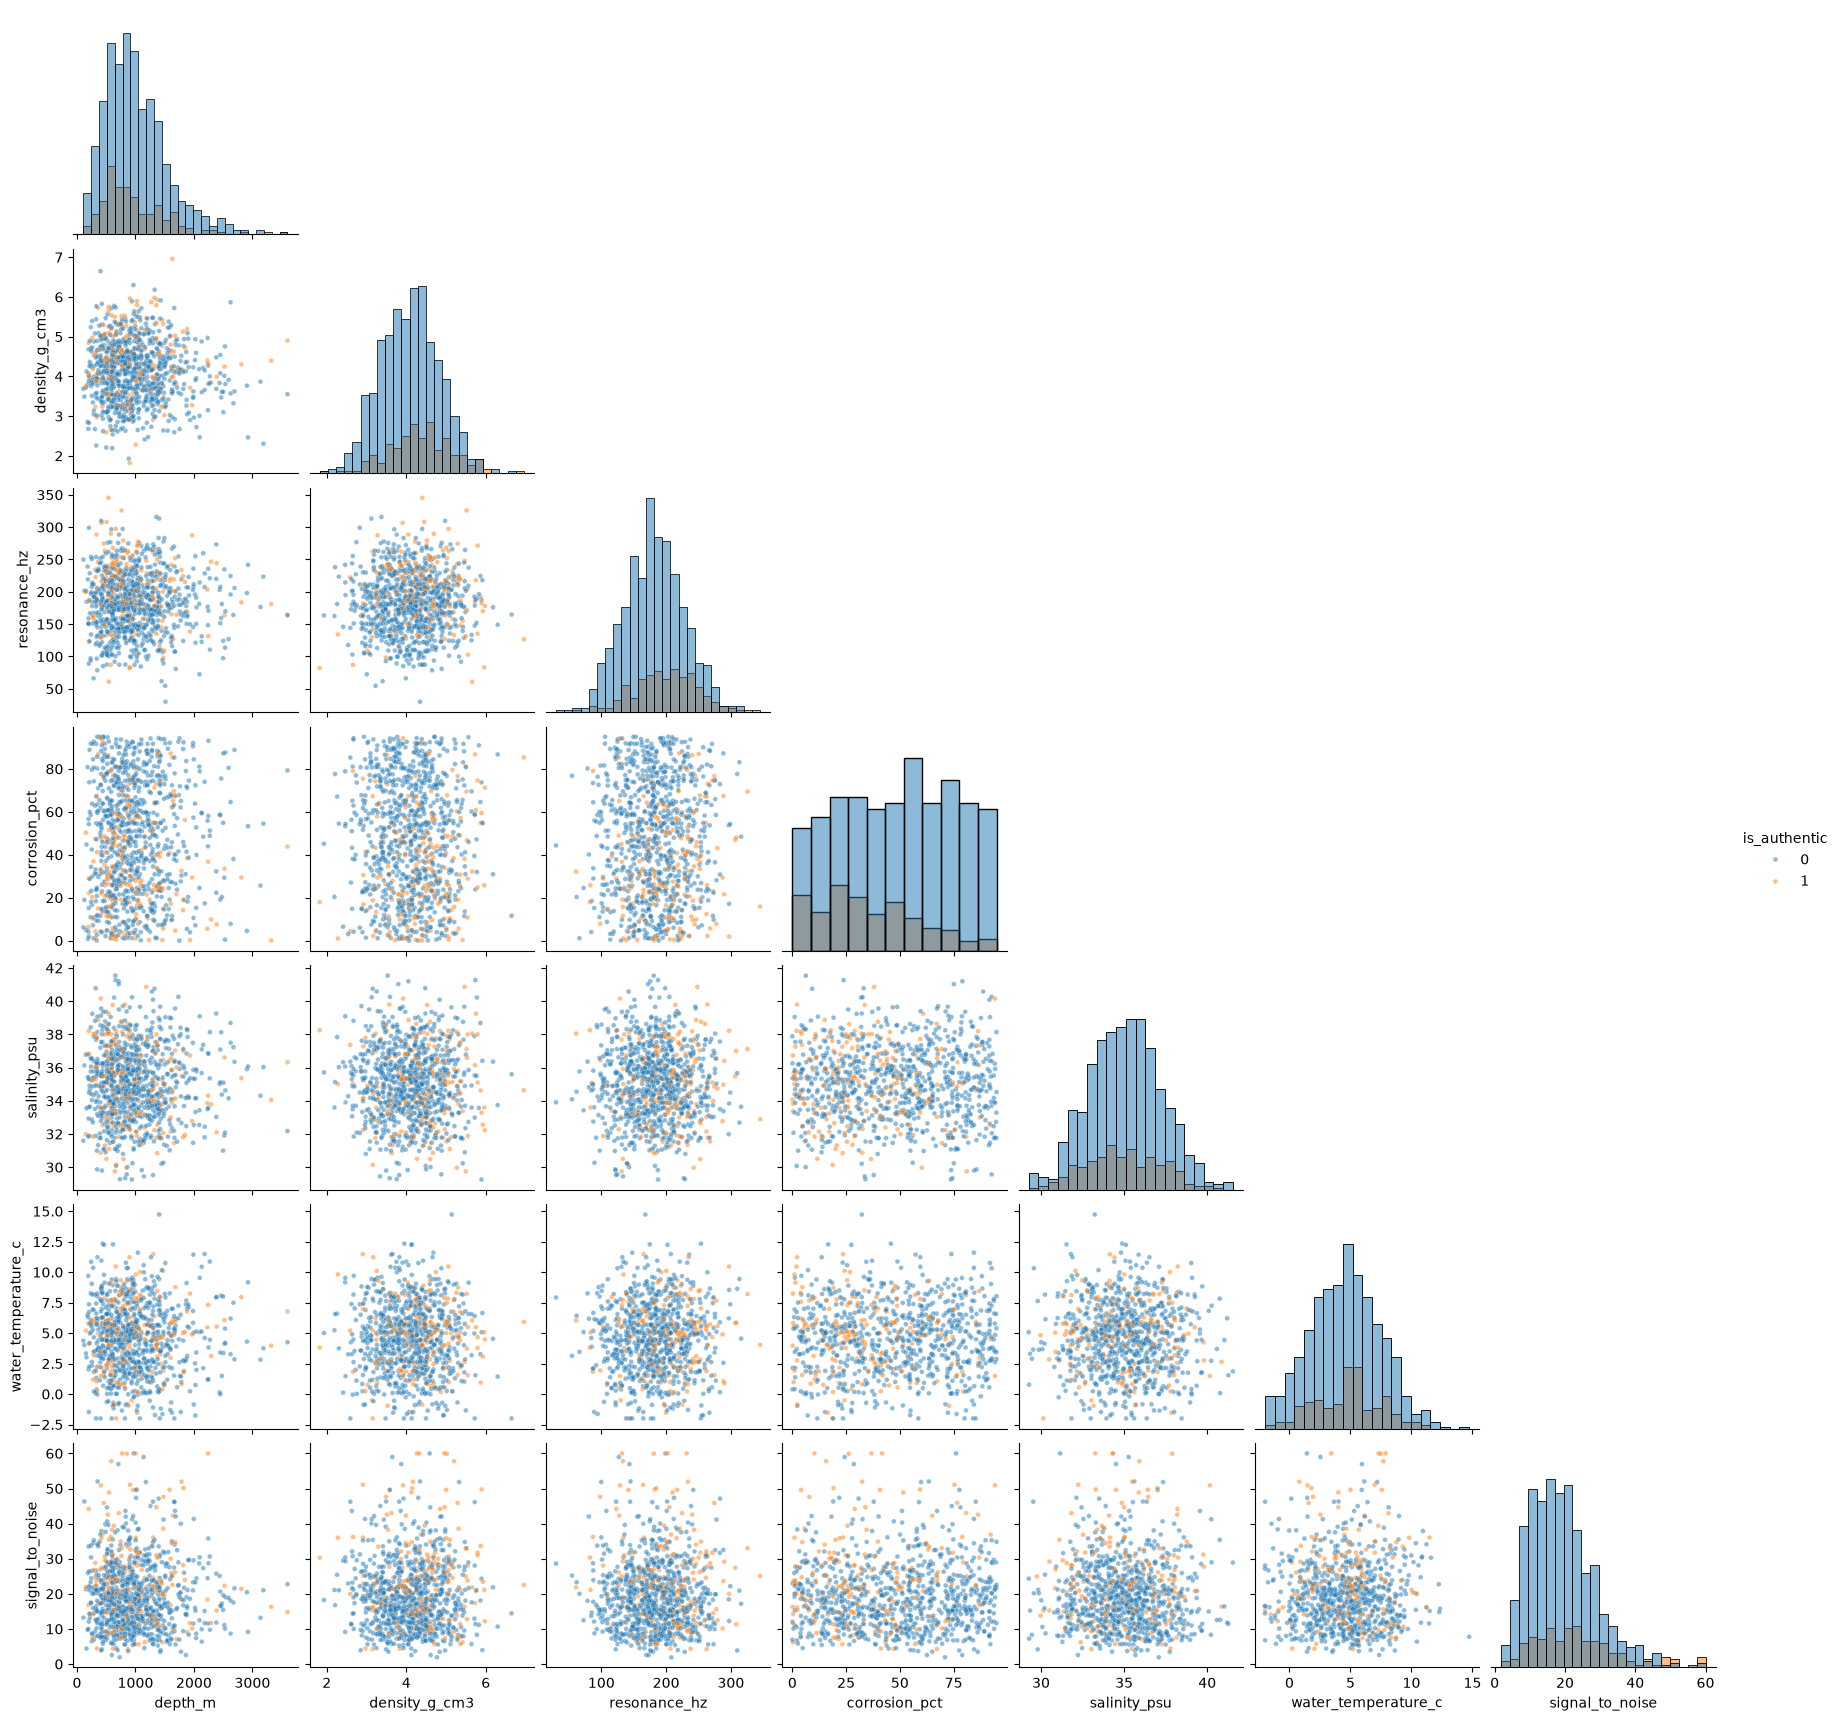

In [96]:
sns.pairplot(
    artifact_train,
    vars=['depth_m', 'density_g_cm3', 'resonance_hz', 'corrosion_pct',
          'salinity_psu', 'water_temperature_c', 'signal_to_noise'],
    hue='is_authentic', corner=True, diag_kind='hist',
    plot_kws={'alpha': 0.5, 's': 12}
)

**Вывод по `pairplot`:** цвета сильно смешиваются. У подлинников чаще ниже коррозия и немного выше резонанс и отношение сигнал/шум, но один признак не отделяет классы без ошибок. Проверим модель, которая использует признаки вместе. `depth_m` и `salinity_psu` на этом графике не показывают очевидного разделения; удалять их только по картинке рано.

Отдельно посмотрим `random_hash_score`: по названию он похож на шумовой столбец, как датчики в первой задаче.

<Axes: xlabel='is_authentic', ylabel='random_hash_score'>

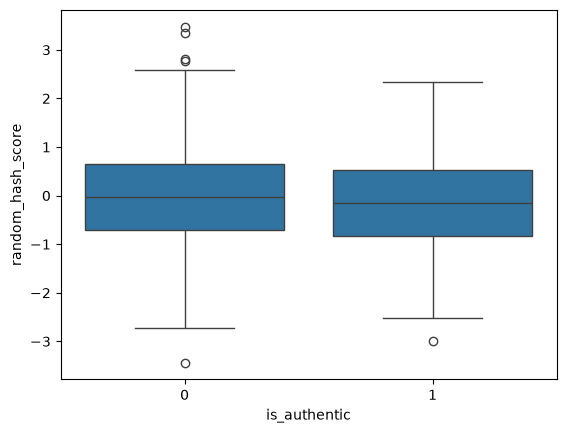

In [85]:
sns.boxplot(data=artifact_train, x='is_authentic', y='random_hash_score')

**Вывод:** распределения `random_hash_score` у классов похожи. Это повод сравнить модель с этим признаком и без него. Сам график не доказывает, что столбец бесполезен: признак может помогать вместе с другими.

### Уберём утечку и подготовим текстовое число

`lab_verdict_after_test` появляется после экспертизы — это утечка из будущего. `artifact_id` нужен для файла ответа, но не для обучения. `collector_code` почти уникален и может помочь запомнить строки вместо поиска закономерности. Удаляем эти три столбца. В `spectrometer_peak_text` убираем ` keV`; `unreadable` станет пропуском.

In [86]:
artifact_drop = ['artifact_id', 'collector_code', 'lab_verdict_after_test']

def artifact_features(table):
    features = table.drop(columns=artifact_drop).copy()
    text_number = features['spectrometer_peak_text'].astype('string').str.replace(' keV', '', regex=False)
    features['spectrometer_peak_text'] = pd.to_numeric(text_number, errors='coerce')
    return features

artifact_ids = artifact_test['artifact_id'].copy()
X_artifact = artifact_features(artifact_train.drop(columns='is_authentic'))
X_artifact_test = artifact_features(artifact_test)
y_artifact = artifact_train['is_authentic'].copy()
print('Нечитаемых значений спектра:', X_artifact['spectrometer_peak_text'].isna().sum())
print('Новые сканеры в test:', set(X_artifact_test['scanner_model'].dropna()) - set(X_artifact['scanner_model'].dropna()))

Нечитаемых значений спектра: 63
Новые сканеры в test: {'MAGNETO-Q'}


**Что изменилось:** 63 строки спектра стали `NaN`; позже заполним их медианой обучения. В test есть новый сканер `MAGNETO-Q`. Функция `prepare_tables` выровняет one-hot столбцы по обучению, поэтому этот новый текст не сломает модель.

### Валидация и простой ориентир

Делим train на 750 обучающих и 250 валидационных строк. `stratify=y_artifact` сохраняет долю подлинников в обеих частях. Сравним будущую модель с простым ответом «всё подделки».

In [87]:
Xa_train, Xa_valid, ya_train, ya_valid = train_test_split(
    X_artifact, y_artifact, test_size=0.25,
    stratify=y_artifact, random_state=RANDOM_STATE
)
print('Доля подлинников:', round(ya_train.mean(), 3), round(ya_valid.mean(), 3))
zero_prediction = np.zeros(len(ya_valid), dtype=int)
print('Всегда 0: accuracy =', round(accuracy_score(ya_valid, zero_prediction), 3),
      'F1 =', round(f1_score(ya_valid, zero_prediction), 3))

Доля подлинников: 0.195 0.192
Всегда 0: accuracy = 0.808 F1 = 0.0


**Ориентир:** доли классов почти одинаковы: 19.5% и 19.2%. Ответ «всё подделки» даёт accuracy 0.808, но F1 = 0: ни один подлинник не найден. Поэтому одной accuracy здесь недостаточно.

### Сравним простые варианты модели

Проверяем `random_hash_score` **с ним и без него**, значения `C = 0.01, 0.1, 1, 10` и `class_weight=None/'balanced'`. Меньше `C` — сильнее регуляризация. `balanced` повышает вес редкого класса, но может ухудшить вероятности. Так как в ответе нужна вероятность, основной критерий выбора — **минимальный log loss на валидации**. F1 и recall при пороге 0.5 пока смотрим как дополнительную информацию.

В каждом варианте `prepare_tables` вычисляет медианы и масштаб только по `Xa_train`. Валидационные ответы в предобработку не попадают.

In [88]:
def artifact_variant(table, variant):
    result = table.copy()
    if variant == 'без hash':
        result = result.drop(columns='random_hash_score')
    return result

artifact_results = []
for variant in ['все', 'без hash']:
    candidate_train = artifact_variant(Xa_train, variant)
    candidate_valid = artifact_variant(Xa_valid, variant)
    ready_train, ready_valid = prepare_tables(candidate_train, candidate_valid)
    for class_weight in [None, 'balanced']:
        for C in [0.01, 0.1, 1, 10]:
            model = LogisticRegression(C=C, class_weight=class_weight,
                                       max_iter=2000, random_state=RANDOM_STATE)
            model.fit(ready_train, ya_train)
            probabilities = model.predict_proba(ready_valid)[:, 1]
            decisions = (probabilities >= 0.5).astype(int)
            artifact_results.append({'вариант': variant, 'C': C, 'class_weight': str(class_weight),
                                     'log loss': log_loss(ya_valid, probabilities),
                                     'F1 при 0.5': f1_score(ya_valid, decisions),
                                     'recall при 0.5': recall_score(ya_valid, decisions)})

artifact_results = pd.DataFrame(artifact_results).sort_values('log loss')
artifact_results.round(3)

,вариант,C,class_weight,log loss,F1 при 0.5,recall при 0.5
1,все,0.10,None,0.391,0.324,0.229
9,без hash,0.10,None,0.392,0.348,0.250
2,все,1.00,None,0.393,0.488,0.417
3,все,10.00,None,0.394,0.500,0.438
10,без hash,1.00,None,0.394,0.488,0.417
11,без hash,10.00,None,0.396,0.476,0.417
0,все,0.01,None,0.423,0.115,0.062
8,без hash,0.01,None,0.424,0.040,0.021
5,все,0.10,balanced,0.541,0.504,0.708
13,без hash,0.10,balanced,0.543,0.471,0.667


**Вывод из таблицы:** минимальный log loss ≈ 0.391 у варианта `все`, `C=0.1`, без `balanced`. Без `random_hash_score` получилось ≈ 0.392: разница очень мала, поэтому график не давал оснований уверенно удалить столбец. `balanced` повышает recall при пороге 0.5, но здесь ухудшает log loss. Для итогового решения возьмём строку с наименьшим log loss.

### Выберем порог для ответа 0/1

`predict_proba` даёт вероятность класса 1. Если порог меньше 0.5, модель чаще называет предмет подлинником: recall обычно растёт, а ложных тревог может стать больше. Проверим 0.35, 0.5 и 0.65; выберем порог с наибольшим **F1 на валидации**. На log loss порог не влияет.

In [ ]:
best_artifact = artifact_results.iloc[0]
best_variant = best_artifact['вариант']
best_C = best_artifact['C']
best_weight = None if best_artifact['class_weight'] == 'None' else 'balanced'
ready_artifact_train, ready_artifact_valid = prepare_tables(
    artifact_variant(Xa_train, best_variant), artifact_variant(Xa_valid, best_variant)
)
best_artifact_model = LogisticRegression(C=best_C, class_weight=best_weight,
                                         max_iter=2000, random_state=RANDOM_STATE)
best_artifact_model.fit(ready_artifact_train, ya_train)
valid_probabilities = best_artifact_model.predict_proba(ready_artifact_valid)[:, 1]
print('Выбрано:', best_variant, 'C =', best_C, 'class_weight =', best_weight)
print('Log loss:', round(log_loss(ya_valid, valid_probabilities), 3))

threshold_rows = []
for threshold in [0.35, 0.5, 0.65]:
    decisions = (valid_probabilities >= threshold).astype(int)
    threshold_rows.append({'порог': threshold,
                           'accuracy': accuracy_score(ya_valid, decisions),
                           'precision': precision_score(ya_valid, decisions, zero_division=0),
                           'recall': recall_score(ya_valid, decisions, zero_division=0),
                           'F1': f1_score(ya_valid, decisions, zero_division=0)})
threshold_results = pd.DataFrame(threshold_rows).sort_values('F1', ascending=False)
threshold_results.round(3)

Выбрано: все C = 0.1 class_weight = None
Log loss: 0.391


,порог,accuracy,precision,recall,F1
0,0.35,0.796,0.472,0.521,0.495
1,0.50,0.816,0.550,0.229,0.324
2,0.65,0.828,0.727,0.167,0.271


ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/zmq/eventloop/zmqstream.py", line 566, in _log_error
    f.result()
    ~~~~~~~~^^
  File "/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/ipykernel/kernelbase.py", line 348, in dispatch_control
    await self.process_control(msg)
  File "/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/ipykernel/kernelbase.py", line 354, in process_control
    idents, msg = self.session.feed_identities(msg, copy=False)
                  ~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/jupyter_client/session.py", line 998, in feed_identities
    raise ValueError(msg)
ValueError: DELIM not in msg_list
ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/Users/mkir/.pyenv/versions/3

**Вывод:** порог 0.35 дал наибольший F1 ≈ 0.495. При нём precision ≈ 0.472, recall ≈ 0.521. При пороге 0.65 precision выше (≈ 0.727), но модель находит лишь около 17% подлинников. Выбор порога зависит от того, какие ошибки дороже; без дополнительной информации используем лучший F1 из проверенных порогов.

### Какие ошибки делает модель?

В матрице ошибок строки — правильный класс 0/1, столбцы — прогноз 0/1. Так видно, сколько подделок ошибочно назвали подлинниками и сколько подлинников пропустили.

In [90]:
best_threshold = threshold_results.iloc[0]['порог']
valid_decisions = (valid_probabilities >= best_threshold).astype(int)
print('Порог:', best_threshold)
print(confusion_matrix(ya_valid, valid_decisions))
print('F1:', round(f1_score(ya_valid, valid_decisions), 3))

Порог: 0.35
[[174  28]
 [ 23  25]]
F1: 0.495


**Вывод:** 174 подделки распознаны верно, 28 ошибочно названы подлинниками. Из 48 настоящих предметов модель нашла 25 и пропустила 23. Высокая accuracy ответа «всё подделки» скрывала бы все 48 пропущенных подлинников.

Оценки выше получены на одной валидации, по которой мы выбирали модель и порог, поэтому они могут быть немного оптимистичны. Настоящее качество на test неизвестно: там нет правильных ответов.

### Обучим выбранную модель на всём train и сохраним ответ

Теперь параметры выбраны. Заново подготовим таблицы: медианы, one-hot столбцы и масштаб вычислим по **всем 1000 строкам train**, затем применим к test. В ответе вероятность — число от 0 до 1, а класс получается сравнением с выбранным порогом.

In [91]:
full_artifact, final_artifact = prepare_tables(
    artifact_variant(X_artifact, best_variant), artifact_variant(X_artifact_test, best_variant)
)
final_artifact_model = LogisticRegression(C=best_C, class_weight=best_weight,
                                          max_iter=2000, random_state=RANDOM_STATE)
final_artifact_model.fit(full_artifact, y_artifact)
final_probabilities = final_artifact_model.predict_proba(final_artifact)[:, 1]
artifact_answer = pd.DataFrame({
    'artifact_id': artifact_ids,
    'is_authentic_probability': final_probabilities,
    'is_authentic': (final_probabilities >= best_threshold).astype(int),
})
assert len(artifact_answer) == len(artifact_test) == 1000
assert not artifact_answer.isna().any().any()
assert artifact_answer['artifact_id'].equals(artifact_test['artifact_id'])
assert artifact_answer['is_authentic_probability'].between(0, 1).all()
artifact_answer.to_csv('task2_predictions.csv', index=False)
artifact_answer.head()

,artifact_id,is_authentic_probability,is_authentic
0,ABYSS-404-0000,0.038834,0
1,ABYSS-404-0001,0.074897,0
2,ABYSS-404-0002,0.070828,0
3,ABYSS-404-0003,0.187115,0
4,ABYSS-404-0004,0.233690,0


**Итог:** сохранён файл `task2_predictions.csv` с 1000 строками без пропусков. Вероятность и класс — прогнозы модели, не известные ответы test. Локальные log loss ≈ 0.391 и F1 ≈ 0.495 относятся к валидации.

## Что сделали в обеих задачах

1. Прочитали смысл колонок и удалили данные из будущего.
2. Сохранили ID для ответа, но не учили модель на ID.
3. Перевели текстовые числа в числа; невозможные значения оставили пропусками.
4. Разделили train до вычисления медиан, one-hot колонок и масштаба.
5. Сравнили маленькое число разумных вариантов на одной валидации.
6. Обучили выбранные модели на полном train и сохранили `task1_predictions.csv` и `task2_predictions.csv`.

В CSV по 1000 строк. Они содержат **предсказания**, а не известные правильные ответы test. Если получить новые данные из другого периода или региона, качество надо измерить заново: сдвиг распределения может ухудшить работу модели.